<a href="https://colab.research.google.com/github/SJ174/MLCW/blob/main/MLCW_Task_02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

In [3]:
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


##Data Cleaning

In [4]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

Dataset Shape: (7043, 21)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 

In [5]:
#Converts TotalCharges into a numerical column
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'].str.strip(),
    errors='coerce'
)
print("TotalCharges data type:", df['TotalCharges'].dtype)

print("\nMissing TotalCharges:", df['TotalCharges'].isnull().sum())

TotalCharges data type: float64

Missing TotalCharges: 11


In [6]:
#Replacing missing TotalCharges values with 0
df['TotalCharges'] = df['TotalCharges'].fillna(0)

print("Remaining missing values:")
print(df.isnull().sum())

print("\nTotalCharges data type:")
print(df['TotalCharges'].dtype)

Remaining missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

TotalCharges data type:
float64


The data cleaning process involved converting the TotalCharges column from an object data type into a numerical format using pandas. During this process, 11 empty string values were identified and converted into missing values (NaN).

Further investigation during the EDA revealed that all 11 affected customers had a tenure of zero months. Therefore, the missing TotalCharges values were replaced with zero, as these customers had no accumulated service charges recorded.

No duplicate records were identified during the inspection.


##Dataset Splitting

In [7]:
#Removes customerID from input features
X = df.drop(columns=['customerID', 'Churn'])
#Seperates target variable
y = df['Churn']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

Features shape: (7043, 19)
Target shape: (7043,)

Feature columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']

Target distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training features: (5634, 19)
Testing features: (1409, 19)

Training target: (5634,)
Testing target: (1409,)

Training target distribution:
Churn
No     73.464679
Yes    26.535321
Name: proportion, dtype: float64

Testing target distribution:
Churn
No     73.456352
Yes    26.543648
Name: proportion, dtype: float64


##Categorical Encoding

In [9]:
numerical_features = [
    'tenure',
    'MonthlyCharges',
    'TotalCharges'
]
categorical_features = [
    col for col in X_train.columns
    if col not in numerical_features
]
print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

print("\nNumber of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))

Numerical features:
['tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Number of numerical features: 3
Number of categorical features: 16


In [10]:
#Preprocessing for KNN and Logistic Regression
scaled_preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)
# Preprocessing for Random Forest
unscaled_preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)
print("Preprocessing transformers created successfully.")

Preprocessing transformers created successfully.


In [11]:
#Encodes target variable by converting it to binary values
y_train = y_train.map({'No': 0, 'Yes': 1})
y_test = y_test.map({'No': 0, 'Yes': 1})

print("Training target values:")
print(y_train.value_counts())

print("\nTesting target values:")
print(y_test.value_counts())

Training target values:
Churn
0    4139
1    1495
Name: count, dtype: int64

Testing target values:
Churn
0    1035
1     374
Name: count, dtype: int64


###Data Preprocessing Summary

The dataset was prepared for machine learning by separating the input features from the target variable. The customerID column was excluded as it serves only as a unique identifier and does not provide meaningful predictive information.

The dataset was divided into training (80%) and testing (20%) subsets using stratified sampling to maintain the original churn class distribution.

Numerical and categorical features were identified separately. One-Hot Encoding was selected to convert categorical variables into numerical representations, while StandardScaler was selected to standardise numerical features for algorithms sensitive to feature magnitudes.

Separate preprocessing transformers were created for scaled and unscaled numerical data. Scaling will be applied to KNN and Logistic Regression, while Random Forest will use the original numerical feature values.

Finally, the target variable was converted into binary values, with 'No' represented by 0 and 'Yes' represented by 1.


##KNN Classification

In [12]:
knn_pipeline = Pipeline([
    ('preprocessor', scaled_preprocessor),
    ('classifier', KNeighborsClassifier())
])
print("KNN pipeline created successfully.")

KNN pipeline created successfully.


In [13]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV

#Sets up 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
print("5-fold stratified cross-validation configured.")

5-fold stratified cross-validation configured.


In [14]:
knn_param_grid = {
    'classifier__n_neighbors': [3, 5, 7, 9, 11, 13, 15, 17, 19, 21],
    'classifier__weights': ['uniform', 'distance'],
    'classifier__metric': ['euclidean', 'manhattan']
}
print("Number of hyperparameter combinations:",
      10 * 2 * 2)

Number of hyperparameter combinations: 40


In [15]:
knn_grid_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=knn_param_grid,
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    verbose=1
)
knn_grid_search.fit(X_train, y_train)
print("\nKNN Hyperparameter Tuning Completed!")

Fitting 5 folds for each of 40 candidates, totalling 200 fits

KNN Hyperparameter Tuning Completed!


In [16]:
print("Best KNN Parameters:")
print(knn_grid_search.best_params_)

print("\nBest Cross-Validation F1-Score:")
print(round(knn_grid_search.best_score_, 4))

Best KNN Parameters:
{'classifier__metric': 'euclidean', 'classifier__n_neighbors': 17, 'classifier__weights': 'uniform'}

Best Cross-Validation F1-Score:
0.5932


In [17]:
knn_results = pd.DataFrame(knn_grid_search.cv_results_)

knn_results = knn_results[
    [
        'param_classifier__n_neighbors',
        'param_classifier__weights',
        'param_classifier__metric',
        'mean_test_score',
        'std_test_score',
        'rank_test_score'
    ]
]
knn_results.columns = [
    'K',
    'Weights',
    'Distance Metric',
    'Mean CV F1-Score',
    'Standard Deviation',
    'Rank'
]
knn_results = knn_results.sort_values('Rank')
knn_results.round(4)

,K,Weights,Distance Metric,Mean CV F1-Score,Standard Deviation,Rank
14,17,uniform,euclidean,0.5932,0.0132,1
38,21,uniform,manhattan,0.5926,0.0197,2
18,21,uniform,euclidean,0.5909,0.0201,3
16,19,uniform,euclidean,0.5892,0.0161,4
36,19,uniform,manhattan,0.5890,0.0169,5
12,15,uniform,euclidean,0.5845,0.0138,6
32,15,uniform,manhattan,0.5843,0.0138,7
34,17,uniform,manhattan,0.5822,0.0115,8
10,13,uniform,euclidean,0.5821,0.0174,9
30,13,uniform,manhattan,0.5777,0.0151,10


###KNN Hyperparameter Tuning Results
Hyperparameter tuning was performed using GridSearchCV with five-fold stratified cross-validation. A total of 40 hyperparameter combinations were evaluated by varying the number of neighbours, distance weighting method and distance metric.

The best-performing configuration used 17 neighbours, uniform weighting and the Euclidean distance metric, achieving a mean cross-validation F1-score of 0.5932 with a standard deviation of 0.0132.


In [18]:
#Uses the best KNN model
best_knn = knn_grid_search.best_estimator_

y_pred_knn = best_knn.predict(X_test)

y_prob_knn = best_knn.predict_proba(X_test)[:, 1]

print("KNN test predictions generated successfully.")

KNN test predictions generated successfully.


In [19]:
knn_accuracy = accuracy_score(y_test, y_pred_knn)
knn_precision = precision_score(y_test, y_pred_knn)
knn_recall = recall_score(y_test, y_pred_knn)
knn_f1 = f1_score(y_test, y_pred_knn)
knn_auc = roc_auc_score(y_test, y_prob_knn)

print("KNN Test Performance")
print("-------------------------")
print("Accuracy:", round(knn_accuracy, 4))
print("Precision:", round(knn_precision, 4))
print("Recall:", round(knn_recall, 4))
print("F1-Score:", round(knn_f1, 4))
print("ROC-AUC:", round(knn_auc, 4))

KNN Test Performance
-------------------------
Accuracy: 0.7786
Precision: 0.5871
Recall: 0.5588
F1-Score: 0.5726
ROC-AUC: 0.8226


In [20]:
print("KNN Classification Report")
print(classification_report(
    y_test,
    y_pred_knn,
    target_names=['No Churn', 'Churn']
))

KNN Classification Report
              precision    recall  f1-score   support

    No Churn       0.84      0.86      0.85      1035
       Churn       0.59      0.56      0.57       374

    accuracy                           0.78      1409
   macro avg       0.72      0.71      0.71      1409
weighted avg       0.78      0.78      0.78      1409



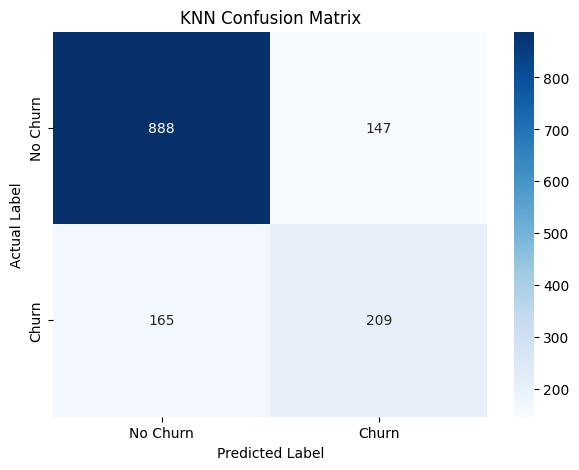

In [21]:
knn_cm = confusion_matrix(y_test, y_pred_knn)

plt.figure(figsize=(7, 5))

sns.heatmap(
    knn_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Churn', 'Churn'],
    yticklabels=['No Churn', 'Churn']
)
plt.title('KNN Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()

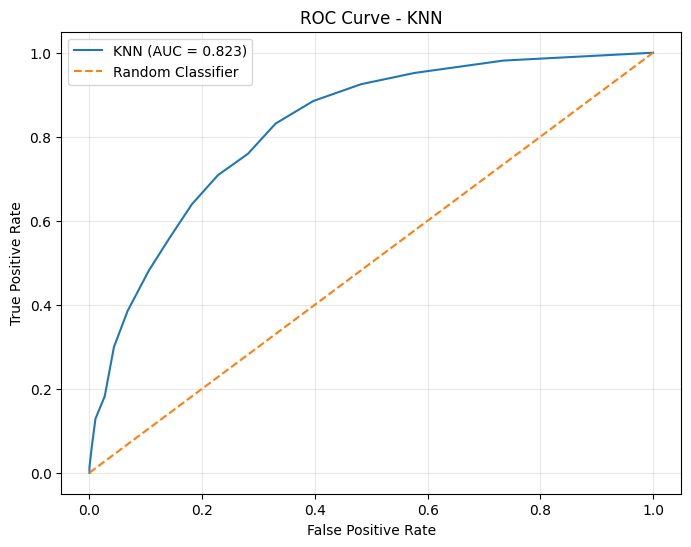

In [22]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob_knn)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f'KNN (AUC = {knn_auc:.3f})'
)
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)
plt.title('ROC Curve - KNN')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [23]:
from sklearn.model_selection import cross_validate

knn_cv_results = cross_validate(
    best_knn,
    X_train,
    y_train,
    cv=cv,
    scoring='f1',
    return_train_score=True,
    n_jobs=-1
)
knn_train_f1 = knn_cv_results['train_score'].mean()
knn_validation_f1 = knn_cv_results['test_score'].mean()

print("KNN Overfitting Analysis")
print("-----------------------------")
print("Mean Training F1-Score:",
      round(knn_train_f1, 4))

print("Mean Validation F1-Score:",
      round(knn_validation_f1, 4))

print("Training-Validation Gap:",
      round(knn_train_f1 - knn_validation_f1, 4))

print("\nIndividual Fold Results:")
print(pd.DataFrame({
    'Training F1': knn_cv_results['train_score'],
    'Validation F1': knn_cv_results['test_score']
}).round(4))

KNN Overfitting Analysis
-----------------------------
Mean Training F1-Score: 0.6317
Mean Validation F1-Score: 0.5932
Training-Validation Gap: 0.0384

Individual Fold Results:
   Training F1  Validation F1
0       0.6242         0.5954
1       0.6397         0.5685
2       0.6277         0.6014
3       0.6333         0.6071
4       0.6334         0.5936


In [24]:
#Stores KNN results
knn_summary = {
    'Model': 'KNN',
    'Best Parameters': knn_grid_search.best_params_,
    'CV F1-Score': knn_grid_search.best_score_,
    'Test Accuracy': knn_accuracy,
    'Test Precision': knn_precision,
    'Test Recall': knn_recall,
    'Test F1-Score': knn_f1,
    'Test ROC-AUC': knn_auc,
    'Training F1-Score': knn_train_f1,
    'Validation F1-Score': knn_validation_f1
}
print("KNN results saved successfully.")

KNN results saved successfully.


###KNN Model Results and Discussion

#### Test Dataset Evaluation

The selected KNN model was evaluated using the previously reserved test dataset containing 1,409 customer records. The model achieved an accuracy of 77.86%, precision of 58.71%, recall of 55.88%, F1-score of 57.26% and ROC-AUC of 0.8226.

The accuracy indicates that the model correctly classified approximately 78% of the test records. However, its precision and recall for the churn class were comparatively lower, indicating that the model has some difficulty reliably identifying customers who are likely to leave.

The ROC-AUC score of 0.8226 indicates that the model has good discriminatory ability when distinguishing between customers who churn and those who remain.

#### Confusion Matrix Analysis

The confusion matrix showed that the model correctly identified 888 customers who did not churn and 209 customers who churned. However, it incorrectly classified 147 non-churning customers as churners and failed to identify 165 customers who actually churned.

This indicates that although the model performs reasonably well at identifying customers who remain with the company, it misses a considerable proportion of actual churners. Improving churn detection remains an important area for potential improvement.

#### Overfitting and Underfitting Analysis

The overfitting and underfitting analysis was conducted using five-fold stratified cross-validation. The model achieved a mean training F1-score of 0.6317 and a mean validation F1-score of 0.5932, resulting in a relatively small training-validation gap of approximately 0.0384.

The relatively small difference between training and validation performance suggests that the model generalises reasonably consistently to unseen data, with no strong indication of severe overfitting.

The individual fold results also demonstrated relatively consistent validation performance. Furthermore, the test F1-score of 0.5726 was reasonably close to the cross-validation F1-score, providing additional evidence of consistent generalisation performance.

#### Overall Discussion

Overall, the KNN classifier demonstrated moderate predictive performance, achieving a test accuracy of 77.86% and an F1-score of 57.26%. Although the model achieved a relatively strong ROC-AUC score, its ability to identify customers who actually churned was more limited, as reflected by its recall of 55.88%.

The results suggest that KNN can distinguish between customers with different churn outcomes to a reasonable extent, but its classification performance could be improved, particularly in identifying customers who are likely to leave. These findings will be considered when comparing KNN with Logistic Regression and Random Forest.


##Logistic Regression Classification

In [25]:
logreg_pipeline = Pipeline([
    ('preprocessor', scaled_preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])
print("Logistic Regression pipeline created successfully.")

Logistic Regression pipeline created successfully.


In [26]:
logreg_param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10, 100],
    'classifier__class_weight': [None, 'balanced']
}
print("Number of hyperparameter combinations:",
      5 * 2)

Number of hyperparameter combinations: 10


In [27]:
logreg_grid_search = GridSearchCV(
    estimator=logreg_pipeline,
    param_grid=logreg_param_grid,
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    verbose=1
)
logreg_grid_search.fit(X_train, y_train)
print("\nLogistic Regression Hyperparameter Tuning Completed!")

Fitting 5 folds for each of 10 candidates, totalling 50 fits

Logistic Regression Hyperparameter Tuning Completed!


In [28]:
print("Best Logistic Regression Parameters:")
print(logreg_grid_search.best_params_)

print("\nBest Cross-Validation F1-Score:")
print(round(logreg_grid_search.best_score_, 4))

Best Logistic Regression Parameters:
{'classifier__C': 0.1, 'classifier__class_weight': 'balanced'}

Best Cross-Validation F1-Score:
0.6288


In [29]:
logreg_results = pd.DataFrame(logreg_grid_search.cv_results_)

logreg_results = logreg_results[
    [
        'param_classifier__C',
        'param_classifier__class_weight',
        'mean_test_score',
        'std_test_score',
        'rank_test_score'
    ]
]
logreg_results.columns = [
    'Regularisation Strength (C)',
    'Class Weight',
    'Mean CV F1-Score',
    'Standard Deviation',
    'Rank'
]
logreg_results = logreg_results.sort_values('Rank')
logreg_results.round(4)

,Regularisation Strength (C),Class Weight,Mean CV F1-Score,Standard Deviation,Rank
3,0.10,balanced,0.6288,0.0213,1
5,1.00,balanced,0.6282,0.0231,2
7,10.00,balanced,0.6274,0.0239,3
9,100.00,balanced,0.6272,0.0233,4
1,0.01,balanced,0.6269,0.0191,5
8,100.00,None,0.5974,0.0288,6
6,10.00,None,0.5973,0.0298,7
4,1.00,None,0.5924,0.0298,8
2,0.10,None,0.5894,0.0281,9
0,0.01,None,0.5809,0.0279,10


In [30]:
#Uses the best Logistic Regression model
best_logreg = logreg_grid_search.best_estimator_

y_pred_logreg = best_logreg.predict(X_test)

y_prob_logreg = best_logreg.predict_proba(X_test)[:, 1]

print("Logistic Regression Test Evaluation Completed!")

Logistic Regression Test Evaluation Completed!


In [31]:
logreg_accuracy = accuracy_score(y_test, y_pred_logreg)
logreg_precision = precision_score(y_test, y_pred_logreg)
logreg_recall = recall_score(y_test, y_pred_logreg)
logreg_f1 = f1_score(y_test, y_pred_logreg)
logreg_roc_auc = roc_auc_score(y_test, y_prob_logreg)

print("Logistic Regression Test Results")
print("---------------------------------")
print(f"Accuracy:  {logreg_accuracy:.4f}")
print(f"Precision: {logreg_precision:.4f}")
print(f"Recall:    {logreg_recall:.4f}")
print(f"F1-Score:  {logreg_f1:.4f}")
print(f"ROC-AUC:   {logreg_roc_auc:.4f}")

Logistic Regression Test Results
---------------------------------
Accuracy:  0.7417
Precision: 0.5087
Recall:    0.7861
F1-Score:  0.6176
ROC-AUC:   0.8408


In [32]:
print("Classification Report:")
print(classification_report(y_test, y_pred_logreg))

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.73      0.80      1035
           1       0.51      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.76      1409



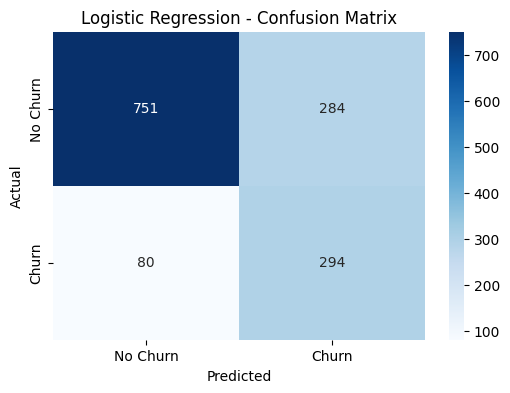

In [33]:
cm_logreg = confusion_matrix(y_test, y_pred_logreg)

plt.figure(figsize=(6, 4))
sns.heatmap(cm_logreg, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Churn', 'Churn'],
            yticklabels=['No Churn', 'Churn'])
plt.title('Logistic Regression - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

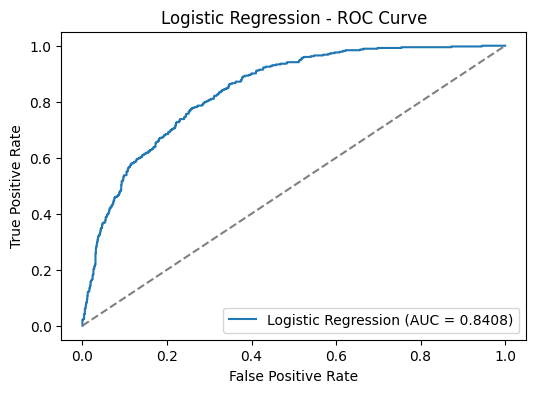

In [34]:
fpr_logreg, tpr_logreg, thresholds_logreg = roc_curve(
    y_test, y_prob_logreg
)
plt.figure(figsize=(6, 4))
plt.plot(fpr_logreg, tpr_logreg,
         label=f'Logistic Regression (AUC = {logreg_roc_auc:.4f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='grey')

plt.title('Logistic Regression - ROC Curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()

In [35]:
logreg_cv_scores = cross_validate(
    best_logreg,
    X_train,
    y_train,
    cv=cv,
    scoring='f1',
    return_train_score=True,
    n_jobs=-1
)
logreg_train_f1 = logreg_cv_scores['train_score'].mean()
logreg_val_f1 = logreg_cv_scores['test_score'].mean()

print("Logistic Regression Overfitting Analysis")
print("----------------------------------------")
print(f"Mean Training F1-Score:   {logreg_train_f1:.4f}")
print(f"Mean Validation F1-Score: {logreg_val_f1:.4f}")
print(f"Difference:               {logreg_train_f1 - logreg_val_f1:.4f}")

Logistic Regression Overfitting Analysis
----------------------------------------
Mean Training F1-Score:   0.6340
Mean Validation F1-Score: 0.6288
Difference:               0.0052


In [36]:
#Stores Logistic Regression results
logreg_summary = {
    'Model': 'Logistic Regression',
    'Best Parameters': logreg_grid_search.best_params_,
    'CV F1-Score': logreg_grid_search.best_score_,
    'Test Accuracy': logreg_accuracy,
    'Test Precision': logreg_precision,
    'Test Recall': logreg_recall,
    'Test F1-Score': logreg_f1,
    'Test ROC-AUC': logreg_roc_auc,
    'Training F1-Score': logreg_train_f1,
    'Validation F1-Score': logreg_val_f1
}
print("Logistic Regression results saved successfully.")

Logistic Regression results saved successfully.


### Logistic Regression Model Results and Discussion

#### Hyperparameter Tuning

Logistic Regression was implemented using a pipeline incorporating the previously defined preprocessing steps, including standardisation of numerical features and one-hot encoding of categorical features. Hyperparameter tuning was performed using GridSearchCV with five-fold stratified cross-validation, evaluating 10 combinations of regularisation strength (C) and class weight configurations. The F1-score was selected as the optimisation metric due to the class imbalance in the dataset.

The optimal configuration consisted of a regularisation strength of C = 0.1 and `class_weight='balanced'`, achieving a mean cross-validation F1-score of 0.6288. The results indicated that using balanced class weights improved performance compared to configurations without class weighting.

#### Test Dataset Evaluation

The selected Logistic Regression model was evaluated using the previously reserved test dataset containing 1,409 customer records. The model achieved an accuracy of 74.17%, precision of 50.87%, recall of 78.61%, F1-score of 61.76% and ROC-AUC of 0.8408.

The recall score indicates that the model successfully identified approximately 79% of actual churn customers. However, its relatively lower precision suggests that a considerable number of customers predicted to churn did not actually cancel their subscriptions. The ROC-AUC score of 0.8408 indicates good discriminatory ability when distinguishing between customers who churn and those who remain.

#### Confusion Matrix Analysis

The confusion matrix showed that the model correctly identified 751 customers who did not churn and 294 customers who churned. However, it incorrectly classified 284 non-churning customers as churners and failed to identify 80 customers who actually churned.

Compared to KNN, Logistic Regression successfully identified more actual churners but also generated more false positive predictions. This demonstrates its stronger ability to detect potential churn customers, although this comes at the expense of lower precision.

#### Overfitting and Underfitting Analysis

The overfitting and underfitting analysis was conducted using five-fold stratified cross-validation. The model achieved a mean training F1-score of 0.6340 and a mean validation F1-score of 0.6288, resulting in a small training-validation gap of approximately 0.0052.

The relatively small difference between training and validation performance suggests that the model generalises consistently across the cross-validation folds, with no strong indication of substantial overfitting. However, these results should be interpreted as an indicative diagnostic because the same cross-validation folds were used during hyperparameter selection.

#### Overall Discussion

Overall, Logistic Regression demonstrated better performance than KNN in terms of recall, F1-score and ROC-AUC. Although its accuracy and precision were lower, it was more effective at identifying customers who were likely to churn. This is particularly relevant in customer retention applications, where identifying potential churners is an important objective.

The results suggest that Logistic Regression provides a promising approach for predicting customer churn. Its performance will be further compared with KNN and Random Forest to determine the most suitable classification model.

##Random Forest Classification

In [37]:
rf_pipeline = Pipeline([
    ('preprocessor', unscaled_preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])
print("Random Forest pipeline created successfully.")

Random Forest pipeline created successfully.


In [38]:
rf_param_grid = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [None, 10, 20],
    'classifier__min_samples_split': [2, 5],
    'classifier__class_weight': [None, 'balanced']
}
print("Number of hyperparameter combinations:",
      2 * 3 * 2 * 2)

Number of hyperparameter combinations: 24


In [39]:
rf_grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    verbose=1
)
rf_grid_search.fit(X_train, y_train)
print("\nRandom Forest Hyperparameter Tuning Completed!")

Fitting 5 folds for each of 24 candidates, totalling 120 fits

Random Forest Hyperparameter Tuning Completed!


In [40]:
print("Best Random Forest Parameters:")
print(rf_grid_search.best_params_)

print("\nBest Cross-Validation F1-Score:")
print(round(rf_grid_search.best_score_, 4))

Best Random Forest Parameters:
{'classifier__class_weight': 'balanced', 'classifier__max_depth': 10, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 200}

Best Cross-Validation F1-Score:
0.6303


In [41]:
rf_results = pd.DataFrame(rf_grid_search.cv_results_)

rf_results = rf_results[
    [
        'param_classifier__n_estimators',
        'param_classifier__max_depth',
        'param_classifier__min_samples_split',
        'param_classifier__class_weight',
        'mean_test_score',
        'std_test_score',
        'rank_test_score'
    ]
]
rf_results.columns = [
    'Number of Trees',
    'Maximum Depth',
    'Minimum Samples Split',
    'Class Weight',
    'Mean CV F1-Score',
    'Standard Deviation',
    'Rank'
]
rf_results = rf_results.sort_values('Rank')
rf_results.round(4)

,Number of Trees,Maximum Depth,Minimum Samples Split,Class Weight,Mean CV F1-Score,Standard Deviation,Rank
17,200,10,2,balanced,0.6303,0.0220,1
19,200,10,5,balanced,0.6284,0.0210,2
16,100,10,2,balanced,0.6274,0.0213,3
18,100,10,5,balanced,0.6260,0.0186,4
23,200,20,5,balanced,0.6078,0.0202,5
15,200,None,5,balanced,0.6074,0.0224,6
22,100,20,5,balanced,0.6031,0.0218,7
14,100,None,5,balanced,0.6006,0.0183,8
6,100,10,5,None,0.5841,0.0150,9
5,200,10,2,None,0.5835,0.0231,10


In [42]:
#Uses the best Random Forest model
best_rf = rf_grid_search.best_estimator_

y_pred_rf = best_rf.predict(X_test)

y_prob_rf = best_rf.predict_proba(X_test)[:, 1]

print("Random Forest Test Evaluation Completed!")

Random Forest Test Evaluation Completed!


In [43]:
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)
rf_roc_auc = roc_auc_score(y_test, y_prob_rf)

print("Random Forest Test Results")
print("--------------------------")
print(f"Accuracy:  {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall:    {rf_recall:.4f}")
print(f"F1-Score:  {rf_f1:.4f}")
print(f"ROC-AUC:   {rf_roc_auc:.4f}")

Random Forest Test Results
--------------------------
Accuracy:  0.7679
Precision: 0.5481
Recall:    0.7166
F1-Score:  0.6211
ROC-AUC:   0.8399


In [44]:
print("Classification Report:")
print(classification_report(y_test, y_pred_rf))

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.79      0.83      1035
           1       0.55      0.72      0.62       374

    accuracy                           0.77      1409
   macro avg       0.72      0.75      0.73      1409
weighted avg       0.80      0.77      0.78      1409



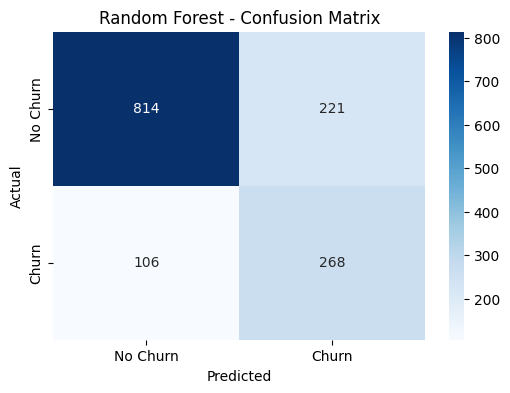

In [45]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 4))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Churn', 'Churn'],
            yticklabels=['No Churn', 'Churn'])
plt.title('Random Forest - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

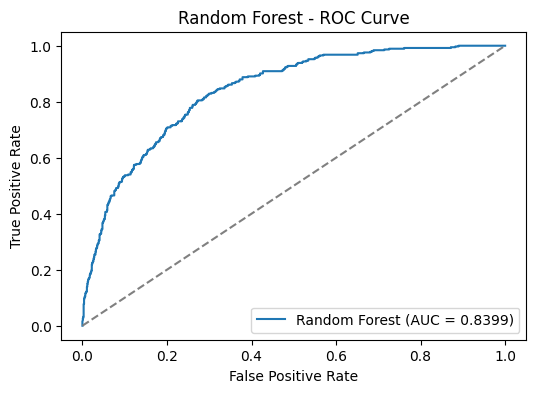

In [46]:
fpr_rf, tpr_rf, thresholds_rf = roc_curve(
    y_test, y_prob_rf
)
plt.figure(figsize=(6, 4))
plt.plot(fpr_rf, tpr_rf,
         label=f'Random Forest (AUC = {rf_roc_auc:.4f})')

plt.plot([0, 1], [0, 1], linestyle='--', color='grey')

plt.title('Random Forest - ROC Curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()

In [47]:
rf_cv_scores = cross_validate(
    best_rf,
    X_train,
    y_train,
    cv=cv,
    scoring='f1',
    return_train_score=True,
    n_jobs=-1
)
rf_train_f1 = rf_cv_scores['train_score'].mean()
rf_val_f1 = rf_cv_scores['test_score'].mean()

print("Random Forest Overfitting Analysis")
print("----------------------------------")
print(f"Mean Training F1-Score:   {rf_train_f1:.4f}")
print(f"Mean Validation F1-Score: {rf_val_f1:.4f}")
print(f"Difference:               {rf_train_f1 - rf_val_f1:.4f}")

Random Forest Overfitting Analysis
----------------------------------
Mean Training F1-Score:   0.7995
Mean Validation F1-Score: 0.6303
Difference:               0.1691


In [48]:
rf_summary = {
    'Model': 'Random Forest',
    'Best Parameters': rf_grid_search.best_params_,
    'CV F1-Score': rf_grid_search.best_score_,
    'Test Accuracy': rf_accuracy,
    'Test Precision': rf_precision,
    'Test Recall': rf_recall,
    'Test F1-Score': rf_f1,
    'Test ROC-AUC': rf_roc_auc,
    'Training F1-Score': rf_train_f1,
    'Validation F1-Score': rf_val_f1
}
print("Random Forest results saved successfully.")

Random Forest results saved successfully.


###Random Forest Model Results and Discussion

#### Hyperparameter Tuning

Random Forest was implemented using a pipeline incorporating the unscaled preprocessing transformer, which applies one-hot encoding to categorical features without standardising numerical features. Hyperparameter tuning was performed using GridSearchCV with five-fold stratified cross-validation, evaluating 24 different combinations of hyperparameters. The F1-score was selected as the optimisation metric due to the class imbalance in the dataset.

The optimal configuration consisted of 200 trees, a maximum depth of 10, a minimum samples split of 2 and `class_weight='balanced'`. This configuration achieved a mean cross-validation F1-score of 0.6303. The results also indicated that configurations using balanced class weights generally performed better than those without class weighting.

#### Test Dataset Evaluation

The selected Random Forest model was evaluated using the reserved test dataset containing 1,409 customer records. It achieved an accuracy of 76.79%, precision of 54.81%, recall of 71.66%, F1-score of 62.11% and ROC-AUC of 0.8399.

The model successfully identified approximately 72% of actual churn customers. Its precision indicates that approximately 55% of customers predicted to churn actually cancelled their subscriptions. The ROC-AUC score of 0.8399 demonstrates good discriminatory ability when distinguishing between churn and non-churn customers.

#### Confusion Matrix Analysis

The confusion matrix showed that the model correctly classified 814 non-churning customers and 268 churning customers. However, it incorrectly classified 221 non-churning customers as churners and failed to identify 106 customers who actually churned.

Compared with Logistic Regression, Random Forest generated fewer false positive predictions but also missed more actual churners. This reflects its higher precision but lower recall.

#### Overfitting and Underfitting Analysis

The overfitting and underfitting analysis was conducted using five-fold stratified cross-validation. The model achieved a mean training F1-score of 0.7995 and a mean validation F1-score of 0.6303, resulting in a difference of approximately 0.1691.

The substantial gap between training and validation performance suggests that the model exhibits overfitting. This indicates that the model learns the training data considerably better than unseen validation data. However, its test F1-score of 0.6211 is relatively close to its validation F1-score, suggesting that its performance on the independent test dataset remains reasonably consistent with the cross-validation results.

#### Overall Discussion

Overall, Random Forest achieved the highest test F1-score among the three implemented algorithms. It demonstrated a reasonable balance between precision and recall, while also achieving good accuracy and ROC-AUC. However, the noticeable training-validation gap indicates a degree of overfitting, which should be considered when assessing its generalisation ability.

Its performance will be compared with KNN and Logistic Regression to determine the most suitable model for predicting customer churn.

##Model Comparison and Evaluation

In [49]:
#Combines results from all three models
model_comparison = pd.DataFrame([
    knn_summary,
    logreg_summary,
    rf_summary
])
#Selects the evaluation metrics for comparison
comparison_metrics = model_comparison[
    [
        'Model',
        'CV F1-Score',
        'Test Accuracy',
        'Test Precision',
        'Test Recall',
        'Test F1-Score',
        'Test ROC-AUC'
    ]
]
#Sorts models based on test F1-score
comparison_metrics = comparison_metrics.sort_values(
    by='Test F1-Score',
    ascending=False
)
comparison_metrics.round(4)

,Model,CV F1-Score,Test Accuracy,Test Precision,Test Recall,Test F1-Score,Test ROC-AUC
2,Random Forest,0.6303,0.7679,0.5481,0.7166,0.6211,0.8399
1,Logistic Regression,0.6288,0.7417,0.5087,0.7861,0.6176,0.8408
0,KNN,0.5932,0.7786,0.5871,0.5588,0.5726,0.8226


In [50]:
#Overfitting comparison
overfitting_comparison = model_comparison[
    [
        'Model',
        'Training F1-Score',
        'Validation F1-Score'
    ]
].copy()
overfitting_comparison['Train-Validation Gap'] = (
    overfitting_comparison['Training F1-Score'] -
    overfitting_comparison['Validation F1-Score']
)
overfitting_comparison.round(4)

,Model,Training F1-Score,Validation F1-Score,Train-Validation Gap
0,KNN,0.6317,0.5932,0.0384
1,Logistic Regression,0.6340,0.6288,0.0052
2,Random Forest,0.7995,0.6303,0.1691


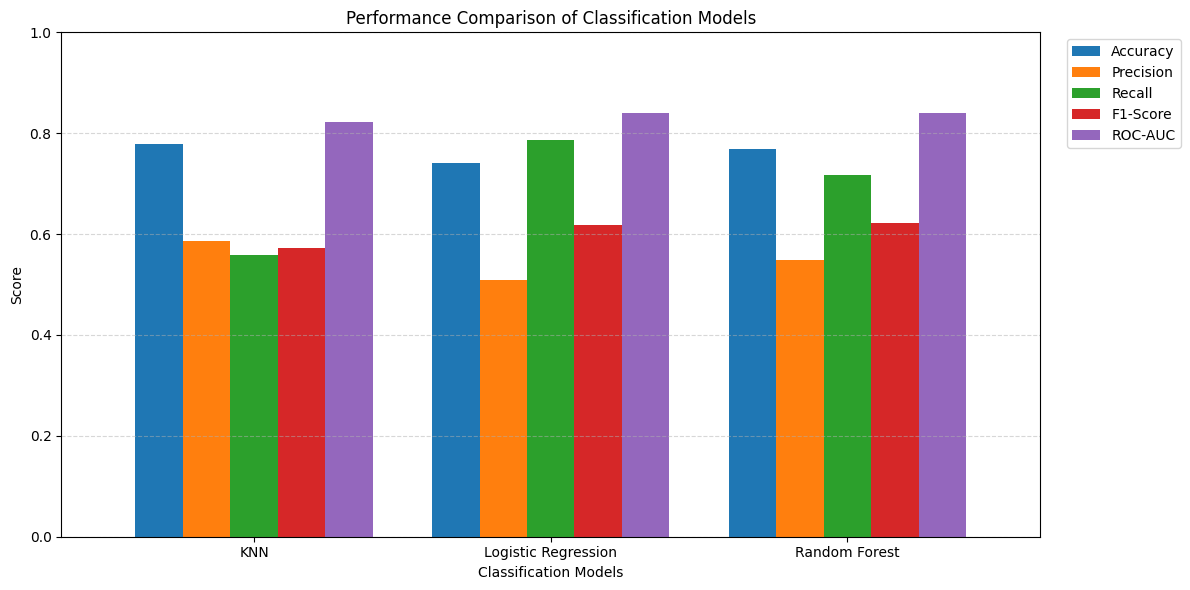

In [51]:
metrics_to_plot = [
    'Test Accuracy',
    'Test Precision',
    'Test Recall',
    'Test F1-Score',
    'Test ROC-AUC'
]
plot_data = model_comparison.set_index('Model')[metrics_to_plot]

plot_data.plot(
    kind='bar',
    figsize=(12, 6),
    width=0.8
)
plt.title('Performance Comparison of Classification Models')
plt.xlabel('Classification Models')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(
    ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'],
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

###Overall Model Comparison and Discussion

The three classification algorithms were compared using their cross-validation F1-scores, test evaluation metrics and training-validation performance to assess their predictive capabilities and generalisation behaviour.

####Comparative Performance

KNN achieved the highest test accuracy of 77.86% and precision of 58.71%. However, its recall of 55.88% was the lowest among the three algorithms, indicating that it failed to identify a considerable proportion of actual churn customers.

Logistic Regression achieved the highest recall of 78.61% and ROC-AUC of 0.8408. This demonstrates its ability to identify a larger proportion of actual churners and distinguish between the two customer classes. However, its precision of 50.87% indicates a relatively high number of false positive predictions.

Random Forest achieved the highest test F1-score of 62.11%, marginally outperforming Logistic Regression (61.76%). It also achieved an accuracy of 76.79% and ROC-AUC of 0.8399, demonstrating reasonably balanced predictive performance. However, its advantage in F1-score over Logistic Regression was relatively small.

####Generalisation and Overfitting Comparison

The training-validation performance comparison revealed differences in the generalisation behaviour of the three algorithms. Logistic Regression achieved the smallest training-validation gap of 0.0052, followed by KNN with a gap of 0.0384. This suggests that both models maintained relatively consistent performance across training and validation folds.

Random Forest exhibited a considerably larger gap of 0.1691, indicating potential overfitting. Although its training performance was substantially higher, its validation performance was comparable to that of Logistic Regression.

####Overall Model Selection

Based on the evaluation results, Random Forest achieved the highest test F1-score and is therefore the strongest performer according to this metric. However, its advantage over Logistic Regression was marginal, and its larger training-validation gap should be considered.

Logistic Regression demonstrated the strongest ability to identify actual churn customers and the most consistent training-validation performance. Therefore, it could be a more suitable choice in situations where identifying as many potential churners as possible is the primary objective.

Overall, Random Forest and Logistic Regression demonstrated comparable predictive performance, with their suitability depending on the evaluation priorities and business requirements. KNN achieved the highest accuracy and precision but was less effective at identifying actual churn customers.